# Analytics Report & Insights
## Retail Sales Performance Analysis

**Project 5 | Portfolio Demonstration**

### Project overview
This project demonstrates a complete business analytics and reporting workflow: defining business questions, preparing and analyzing data, creating visualizations, interpreting findings, preparing an executive summary, and recommending practical actions.

**Dataset note:** The notebook creates a deterministic, synthetic retail orders dataset for educational demonstration. It is not a real company's data. The analysis is reproducible and can be adapted to an organization's actual sales records.

## 1. Business objectives and questions

**Business objective:** Assess retail sales and profitability performance across product categories, regions, and months to identify where the business is performing well and where management attention may be needed.

The analysis addresses these questions:
1. What are total revenue, total profit, order volume, and average order value?
2. Which product categories and regions contribute most to revenue and profit?
3. How do revenue and profit change over the year?
4. Are higher discounts associated with lower profit margins?
5. Which areas should management prioritize?

**Stakeholders:** Business owner, sales manager, category managers, and regional managers.

**Reporting requirements:** A concise KPI overview, trend and segment comparisons, data-quality checks, clearly labelled charts, findings, and actionable recommendations.

## 2. Tools and libraries

- **Python** – executes the workflow.
- **NumPy** – generates reproducible data and supports numerical calculations.
- **Pandas** – data preparation, aggregation, and quality checks.
- **Matplotlib / Seaborn** – visual exploration and communication.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

## 3. Generate and understand the dataset

Each row represents one order. The generated fields include order date, region, product category, units, unit price, discount rate, revenue, cost, and profit.

In [2]:
n = 1200
dates = pd.to_datetime(rng.choice(pd.date_range("2025-01-01", "2025-12-31", freq="D"), n))
regions = rng.choice(["North", "South", "East", "West"], n, p=[0.28, 0.25, 0.22, 0.25])
categories = rng.choice(["Electronics", "Home & Kitchen", "Clothing", "Beauty"], n, p=[0.28, 0.27, 0.25, 0.20])
units = rng.integers(1, 6, n)
price_map = {"Electronics": 180, "Home & Kitchen": 85, "Clothing": 45, "Beauty": 30}
cost_ratio_map = {"Electronics": 0.72, "Home & Kitchen": 0.62, "Clothing": 0.55, "Beauty": 0.48}
unit_price = np.array([price_map[c] for c in categories]) * rng.uniform(0.75, 1.30, n)
discount = rng.choice([0.00, 0.05, 0.10, 0.15, 0.20, 0.25], n, p=[0.18, 0.18, 0.24, 0.20, 0.14, 0.06])
revenue = units * unit_price * (1 - discount)
cost = units * unit_price * np.array([cost_ratio_map[c] for c in categories])
profit = revenue - cost

df = pd.DataFrame({
    "order_id": [f"ORD-{i:04d}" for i in range(1, n+1)],
    "order_date": dates,
    "region": regions,
    "category": categories,
    "units": units,
    "unit_price": unit_price.round(2),
    "discount_rate": discount,
    "revenue": revenue.round(2),
    "cost": cost.round(2),
    "profit": profit.round(2)
}).sort_values("order_date").reset_index(drop=True)

df["month"] = df["order_date"].dt.to_period("M").astype(str)
df.head()

,order_id,order_date,region,category,units,unit_price,discount_rate,revenue,cost,profit,month
0,ORD-0381,2025-01-02,West,Clothing,2,35.91,0.15,61.05,39.50,21.55,2025-01
1,ORD-0773,2025-01-02,South,Clothing,5,46.42,0.10,208.90,127.66,81.24,2025-01
2,ORD-0901,2025-01-02,East,Clothing,1,34.22,0.20,27.37,18.82,8.55,2025-01
3,ORD-0845,2025-01-02,North,Home & Kitchen,2,68.88,0.15,117.09,85.41,31.68,2025-01
4,ORD-0846,2025-01-02,East,Beauty,4,30.06,0.05,114.22,57.71,56.51,2025-01


## 4. Data inspection and quality checks

Check dimensions, data types, summary statistics, missing values, duplicate order IDs, and basic validity rules before interpreting the results.

In [3]:
print("Dataset shape:", df.shape)
display(df.dtypes.to_frame("data_type"))
display(df.describe(include="all").T)
quality = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique()
})
display(quality)
print("Duplicate order IDs:", df["order_id"].duplicated().sum())
print("Non-positive units:", (df["units"] <= 0).sum())
print("Negative revenue:", (df["revenue"] < 0).sum())

Dataset shape: (1200, 11)


,data_type
order_id,object
order_date,datetime64[ns]
region,object
category,object
units,int64
unit_price,float64
discount_rate,float64
revenue,float64
cost,float64
profit,float64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,1200,1200,ORD-0381,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,1200,NaN,NaN,NaN,2025-07-03 12:54:00,2025-01-02 00:00:00,2025-04-03 00:00:00,2025-07-04 00:00:00,2025-10-04 00:00:00,2025-12-31 00:00:00,NaN
region,1200,4,North,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1200,4,Electronics,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
units,"1,200.00",NaN,NaN,NaN,2.92,1.00,2.00,3.00,4.00,5.00,1.42
unit_price,"1,200.00",NaN,NaN,NaN,93.90,22.53,39.00,73.94,148.84,233.77,63.13
discount_rate,"1,200.00",NaN,NaN,NaN,0.10,0.00,0.05,0.10,0.15,0.25,0.07
revenue,"1,200.00",NaN,NaN,NaN,250.05,17.05,85.52,160.46,334.97,"1,132.00",228.50
cost,"1,200.00",NaN,NaN,NaN,183.07,10.82,52.21,110.61,248.47,841.56,183.09
profit,"1,200.00",NaN,NaN,NaN,66.98,6.14,27.77,50.92,90.41,316.96,53.32


,missing_values,unique_values
order_id,0,1200
order_date,0,351
region,0,4
category,0,4
units,0,5
unit_price,0,1137
discount_rate,0,6
revenue,0,1182
cost,0,1184
profit,0,1150


Duplicate order IDs: 0
Non-positive units: 0
Negative revenue: 0


## 5. KPI calculations

Revenue is the total amount after discounts. Profit is revenue less estimated product cost. Profit margin is total profit divided by total revenue. Average order value (AOV) is total revenue divided by order count.

In [4]:
total_revenue = df["revenue"].sum()
total_profit = df["profit"].sum()
order_count = df["order_id"].nunique()
total_units = df["units"].sum()
aov = total_revenue / order_count
profit_margin = total_profit / total_revenue

kpis = pd.DataFrame({
    "Metric": ["Total revenue", "Total profit", "Orders", "Units sold", "Average order value", "Overall profit margin"],
    "Value": [total_revenue, total_profit, order_count, total_units, aov, profit_margin]
})
display(kpis)

,Metric,Value
0,Total revenue,"300,063.84"
1,Total profit,"80,379.89"
2,Orders,"1,200.00"
3,Units sold,"3,501.00"
4,Average order value,250.05
5,Overall profit margin,0.27


## 6. Category and regional performance

Compare revenue, profit, order count, and profit margin by product category and region. These summaries help identify where sales volume and profitability differ.

In [5]:
category_summary = df.groupby("category").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "count"),
    units=("units", "sum")
)
category_summary["profit_margin"] = category_summary["profit"] / category_summary["revenue"]
category_summary = category_summary.sort_values("revenue", ascending=False)
display(category_summary)

region_summary = df.groupby("region").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "count")
)
region_summary["profit_margin"] = region_summary["profit"] / region_summary["revenue"]
region_summary = region_summary.sort_values("revenue", ascending=False)
display(region_summary)

,revenue,profit,orders,units,profit_margin
category,,,,,
Electronics,"173,954.66","36,126.59",349,1048,0.21
Home & Kitchen,"73,136.63","22,371.14",327,935,0.31
Clothing,"35,064.11","13,507.71",288,854,0.39
Beauty,"17,908.44","8,374.45",236,664,0.47


,revenue,profit,orders,profit_margin
region,,,,
North,"80,574.66","22,151.02",339,0.27
West,"79,809.71","21,696.22",325,0.27
South,"76,730.88","19,898.56",301,0.26
East,"62,948.59","16,634.09",235,0.26


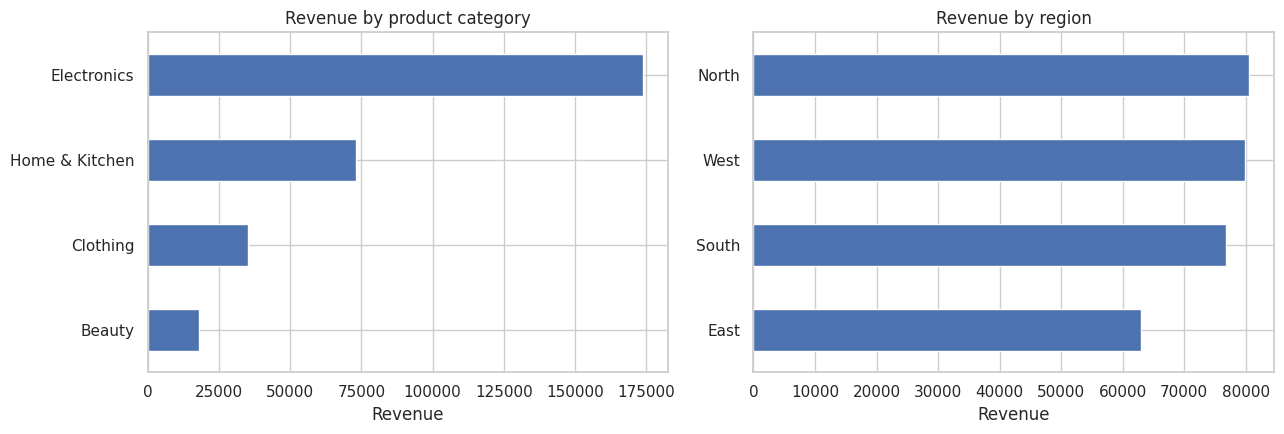

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
category_summary["revenue"].sort_values().plot(kind="barh", ax=axes[0], title="Revenue by product category")
axes[0].set_xlabel("Revenue")
axes[0].set_ylabel("")
region_summary["revenue"].sort_values().plot(kind="barh", ax=axes[1], title="Revenue by region")
axes[1].set_xlabel("Revenue")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## 7. Monthly trend analysis

Monthly aggregation reveals whether revenue and profit are stable, rising, or declining. The line chart presents both measures over the reporting year.

,month,revenue,profit,orders
0,2025-01,"24,873.25","6,698.12",90
1,2025-02,"26,872.22","7,043.49",115
2,2025-03,"19,297.13","5,424.96",89
3,2025-04,"22,607.05","5,989.16",96
4,2025-05,"20,494.51","5,212.22",76
5,2025-06,"29,210.77","8,007.42",116
6,2025-07,"27,286.58","6,909.60",108
7,2025-08,"23,219.15","6,468.19",103
8,2025-09,"28,870.49","7,523.38",100
9,2025-10,"26,911.57","7,563.92",111


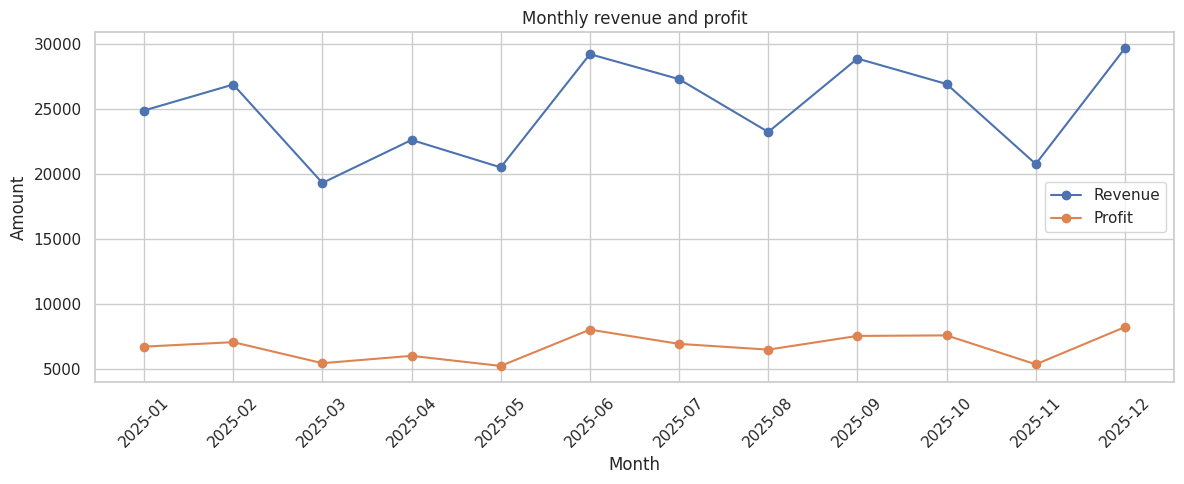

In [7]:
monthly = df.groupby("month").agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "count")
).reset_index()
display(monthly)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month"], monthly["revenue"], marker="o", label="Revenue")
ax.plot(monthly["month"], monthly["profit"], marker="o", label="Profit")
ax.set_title("Monthly revenue and profit")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Discount and profitability relationship

Compare average profit margin across discount bands. This is a descriptive relationship, not proof that discounting alone causes changes in profitability; product mix and order characteristics may also matter.

,revenue,profit,orders,profit_margin
discount_band,,,,
0–5%,"135,137.56","42,501.02",454,0.31
5–10%,"65,976.95","17,892.99",278,0.27
10–15%,"58,412.89","12,995.74",250,0.22
15–20%,"28,772.45","5,575.36",165,0.19
20–25%,"11,763.99","1,414.78",53,0.12


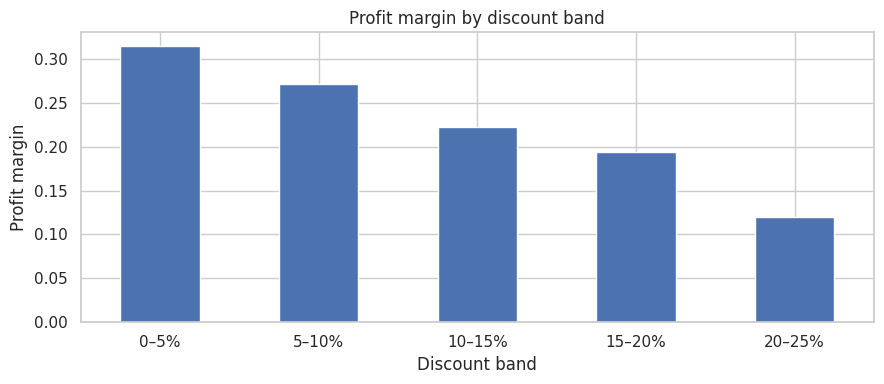

In [8]:
bins = [-0.001, 0.05, 0.10, 0.15, 0.20, 0.25]
labels = ["0–5%", "5–10%", "10–15%", "15–20%", "20–25%"]
df["discount_band"] = pd.cut(df["discount_rate"], bins=bins, labels=labels, include_lowest=True)
discount_summary = df.groupby("discount_band", observed=False).agg(
    revenue=("revenue", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "count")
)
discount_summary["profit_margin"] = discount_summary["profit"] / discount_summary["revenue"]
display(discount_summary)
ax = discount_summary["profit_margin"].plot(kind="bar", figsize=(9, 4), title="Profit margin by discount band")
ax.set_xlabel("Discount band")
ax.set_ylabel("Profit margin")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 9. Key findings and business interpretation

The following cells calculate the leading category, leading region, best and weakest monthly revenue, and the discount-band margin comparison directly from the generated data. Use these outputs as the evidence for the written report.

In [9]:
top_category = category_summary["revenue"].idxmax()
top_region = region_summary["revenue"].idxmax()
best_month = monthly.loc[monthly["revenue"].idxmax(), "month"]
weak_month = monthly.loc[monthly["revenue"].idxmin(), "month"]
lowest_margin_band = discount_summary["profit_margin"].idxmin()
highest_margin_band = discount_summary["profit_margin"].idxmax()

print(f"Top category by revenue: {top_category} (${category_summary.loc[top_category, 'revenue']:,.2f})")
print(f"Top region by revenue: {top_region} (${region_summary.loc[top_region, 'revenue']:,.2f})")
print(f"Highest-revenue month: {best_month}")
print(f"Lowest-revenue month: {weak_month}")
print(f"Highest margin discount band: {highest_margin_band}")
print(f"Lowest margin discount band: {lowest_margin_band}")
print(f"Overall profit margin: {profit_margin:.1%}")

Top category by revenue: Electronics ($173,954.66)
Top region by revenue: North ($80,574.66)
Highest-revenue month: 2025-12
Lowest-revenue month: 2025-03
Highest margin discount band: 0–5%
Lowest margin discount band: 20–25%
Overall profit margin: 26.8%


## 10. Executive summary

The business generated **[insert total revenue]** in revenue and **[insert total profit]** in profit across **[insert order count]** orders. The strongest category and region are identified in the segment summaries. Monthly results highlight the highest- and lowest-revenue periods. Discount-band comparisons help management review whether promotional depth is consistent with profitability objectives.

Replace the bracketed placeholders with the executed KPI and finding outputs before sharing the report with stakeholders.

## 11. Actionable recommendations

1. **Prioritize category-level planning:** Review inventory, merchandising, and campaign plans for the highest-revenue category while monitoring its profit contribution.
2. **Share regional practices:** Investigate what is working in the leading region and test relevant practices in lower-performing regions.
3. **Plan around monthly variation:** Review demand drivers in the strongest and weakest months and align staffing, stock, and campaigns accordingly.
4. **Set discount guardrails:** Evaluate discount bands against margin outcomes; require a profitability check before expanding deep-discount promotions.
5. **Monitor a recurring KPI dashboard:** Track revenue, profit, margin, order count, AOV, and category/region contribution monthly.

Prioritize actions using both revenue and profit; high sales alone do not guarantee strong profitability.

## 12. Limitations and responsible interpretation

- The dataset is synthetic and designed for learning; it does not describe an actual company or market.
- Cost ratios and product prices are illustrative assumptions.
- The analysis is descriptive. It does not establish causal relationships.
- No seasonality, customer-level behavior, marketing spend, returns, shipping costs, or inventory constraints are modeled.
- Recommendations should be validated using actual business data and stakeholder context before implementation.

## 13. Conclusion

This project demonstrates a structured analytics workflow from business-question definition through data-quality checks, KPI calculation, visualization, interpretation, executive communication, and recommendations. It shows how analysis can support business decisions when findings are clearly connected to measurable objectives and interpreted with appropriate limitations.

## 14. References

- Pandas documentation: https://pandas.pydata.org/docs/
- NumPy documentation: https://numpy.org/doc/
- Matplotlib documentation: https://matplotlib.org/stable/
- Seaborn documentation: https://seaborn.pydata.org/